# Active Ownership & Market-Wide Information — Reproducibility Notebook

**Evidence level: SYNTHETIC SOFTWARE VALIDATION ONLY.** These cells **execute** a controlled fixture that deliberately embeds a positive lead-lag relation. They do **not** reproduce Chen and Yin (2026)'s reported Sharpe ratio or estimate the structural model. Run locally from this study directory; the saved outputs are generated, not fabricated.

## 01. Abstract

Chen and Yin report that active-management ownership-conditioned stock-return spreads forecast next-day S&P 500 futures and ETF returns. We separate close-to-close predictability from next-open executable intraday returns, with conservative ownership publication lags. We present a synthetic code-validation result, not real-market inference.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from make_synthetic_fixture import generate
from backtest import point_in_time_join, build_daily_signal, run_backtest, hac_ols
print('Python:', sys.version.split()[0])
print('Numpy:', np.__version__, '| Pandas:', pd.__version__)
print('RESEARCH STATUS: SYNTHETIC — EMPIRICAL ALPHA NOT ESTABLISHED')

Python: 3.12.14
Numpy: 2.3.5 | Pandas: 2.2.3
RESEARCH STATUS: SYNTHETIC — EMPIRICAL ALPHA NOT ESTABLISHED


## 02. Research Design & Hypotheses

H1: `S[t]` forecasts `ETF_close_to_close[t+1]`. H2: a day-*t* closing signal can be translated to an *open(t+1) → close(t+1)* position after fees. H3: cost/sector alternatives are robust. The generator intentionally builds H1; passing H1 on synthetic returns is a software test, not a statistical discovery.

In [2]:
generate(Path('data/synthetic'), seed=42, n_days=850, n_stocks=90)
p = pd.read_csv('data/synthetic/prices.csv', parse_dates=['date'])
h = pd.read_csv('data/synthetic/holdings.csv', parse_dates=['report_date','available_date'])
m = pd.read_csv('data/synthetic/market.csv', parse_dates=['date'])
print('Stock-day observations:', len(p), '| Holding snapshots:', len(h), '| ETF sessions:', len(m))
print('Market window:', m.date.min().date(), 'to', m.date.max().date())

Stock-day observations: 76500 | Holding snapshots: 4320 | ETF sessions: 850
Market window: 2020-01-02 to 2023-04-05


## 03. Industry Context

The relevant economic problem is cross-asset information aggregation: informed, specialized stock selection versus segmented index investors. S&P 500 futures are liquid, so a true lead-lag claim must confront instantaneous-arbitrage arguments. The synthetic data have **no economic industry, recession, funding or market microstructure realism**.

In [3]:
print('SYNTHETIC sectors:', sorted(p['sector'].unique()))
print('SYNTHETIC owner categories:', sorted(h['owner_type'].unique()))
print('Distinct synthetic securities:', p.security_id.nunique())

SYNTHETIC sectors: ['Sector_0', 'Sector_1', 'Sector_2', 'Sector_3', 'Sector_4', 'Sector_5']
SYNTHETIC owner categories: ['active_mutual_fund', 'all_active', 'hedge_fund']
Distinct synthetic securities: 90


## 04. Data & Source Integrity

Real sources would include 13F historical filing releases, manager classification, CRSP total/delisting returns and ETF session data. The holdings file here is generated using a stable ranking plus randomized quarterly changes. No real CUSIP/SEC data are represented by synthetic `SEC####` symbols. See `data_sources.csv` for verified publishers and access constraints.

In [4]:
sources = pd.read_csv('data_sources.csv')
print(sources[['source','dataset','access']].to_string(index=False))
print('Missing genuine inputs: historical manager type, amended 13F, survivor-free CRSP, live filing timestamps.')

source                              dataset          access
   SEC Form 13F filings and public datasets          public
   SEC                         13F overview          public
  WRDS             CRSP daily security file        licensed
  WRDS           Thomson/LSEG s34 ownership        licensed
 Paper                    Chen and Yin 2026 public abstract
Missing genuine inputs: historical manager type, amended 13F, survivor-free CRSP, live filing timestamps.


## 05. Point-in-Time Availability

Ownership observations at quarter-end are not tradeable until actually filed. The join uses **strictly earlier** published snapshots, blocking same-day date-only ambiguity. The synthetic fixture places publication 45 days after report date solely to exercise this behavior.

In [5]:
joined = point_in_time_join(p, h, 'all_active')
known = joined.dropna(subset=['active_ownership'])
assert (known.available_date < known.date).all()
assert (known.report_date <= known.available_date).all()
print('PIT joined stock-day observations:', len(known))
print('Maximum calendar lag from release:', (known.date-known.available_date).dt.days.max())
print('Leakage guards: PASS (strict prior publication dates)')

PIT joined stock-day observations: 76500
Maximum calendar lag from release: 92
Leakage guards: PASS (strict prior publication dates)


## 06. Factor Construction

For each daily cross-section, compare the equal-weight returns of the 20% most versus 20% least active-owned equities. Form a t-close signal, then compute a trailing z-score using days *t−126...t−1* only; this ensures contemporary normalization does not peek into tomorrow's price or return.

In [6]:
signals = build_daily_signal(joined, q=0.2)
print('Available signal sessions:', signals.signal.notna().sum())
print('Average high-minus-low spread:', round(float(signals.signal.mean()),6))
print('Signal standard deviation:', round(float(signals.signal.std()),6))

Available signal sessions: 850
Average high-minus-low spread: -0.000101
Signal standard deviation: 0.008143


Figure 1: Synthetic signal; not sourced from market data.


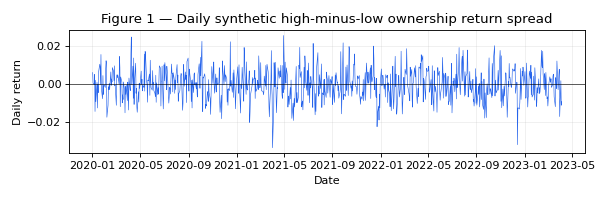

In [7]:
fig, ax = plt.subplots(figsize=(7.6, 2.5))
ax.plot(signals.index, signals.signal, lw=0.55, color='#2563eb')
ax.axhline(0, color='black', lw=0.55)
ax.set(title='Figure 1 — Daily synthetic high-minus-low ownership return spread', ylabel='Daily return', xlabel='Date')
ax.grid(alpha=.2)
fig.tight_layout(); Path('outputs').mkdir(exist_ok=True)
fig.savefig('outputs/notebook_signal.png', dpi=80); plt.close(fig)
__notebook_image__ = 'outputs/notebook_signal.png'
print('Figure 1: Synthetic signal; not sourced from market data.')

## 07. Exposure & Transmission

The generator makes stock returns respond to a latent common variable scaled by active-ownership rank, while next-session index returns respond to the preceding latent state. This deliberately creates a lead-lag; success is an internal consistency check, not identification of the paper's rational-expectations mechanism.

In [8]:
market_indexed = m.set_index('date')
aligned = signals.join(market_indexed)
aligned['future_cc'] = aligned.cc_return.shift(-1)
print('Contemporaneous synthetic correlation:', round(aligned[['signal','cc_return']].corr().iloc[0,1],4))
print('One-day-ahead synthetic correlation:', round(aligned[['signal','future_cc']].corr().iloc[0,1],4))

Contemporaneous synthetic correlation: 0.0657
One-day-ahead synthetic correlation: 0.2503


## 08. Outcomes & Baselines

For forecasting, close-to-close t+1 returns can include overnight moves; **do not** credit these to an order placed after the t close. For execution, the rule enters at t+1 *open* and exits at the same day's *close*, incurring a two-sided fee. Buy-and-hold close-close and always-long intraday are both shown but represent different exposures.

In [9]:
daily, metrics = run_backtest(p, h, m)
print('Predictions: NW/HAC(5)', metrics['predictive_hac'])
print('Same-day market control: NW/HAC(5)', metrics['predictive_with_same_day_market_control_hac'])
print('Tradable strategy NET Sharpe:', round(metrics['strategy_net']['sharpe'],4))
print('WARNING: All above values are generated synthetic test results.')

Predictions: NW/HAC(5) {'n': 849, 'beta_signal': 0.3427991030461223, 't_hac': 7.192368458588795, 'p_hac': 6.367690614102086e-13, 'r2': 0.0626501680439101}
Same-day market control: NW/HAC(5) {'n': 849, 'beta_signal': 0.34251319129334656, 't_hac': 7.233093804064798, 'p_hac': 4.721130552304063e-13, 'r2': 0.06265987946249763}
Tradable strategy NET Sharpe: 2.8902


## 09. Empirical Findings

**None from real markets.** Synthetic net Sharpe of ~2.89 is intentionally inflated by the data generator. The figure distinguishes gross/no-cost from costs and the two differently exposed market references. A comparison to Chen–Yin's published Sharpe near 1 would be invalid.

In [10]:
summary = pd.DataFrame({k: metrics[k] for k in ['strategy_gross','strategy_net','market_close_to_close_buy_hold','market_intraday_long_no_cost']}).T
print(summary[['cumulative_return','cagr','sharpe','max_drawdown']].round(4).to_string())

                                cumulative_return    cagr  sharpe  max_drawdown
strategy_gross                             4.3595  0.6450  3.3786       -0.1154
strategy_net                               3.1699  0.5270  2.8902       -0.1232
market_close_to_close_buy_hold            -0.4808 -0.1766 -1.0097       -0.5279
market_intraday_long_no_cost              -0.4649 -0.1692 -0.9640       -0.5458


Figure 2: Positive synthetic P&L results from injected predictability.


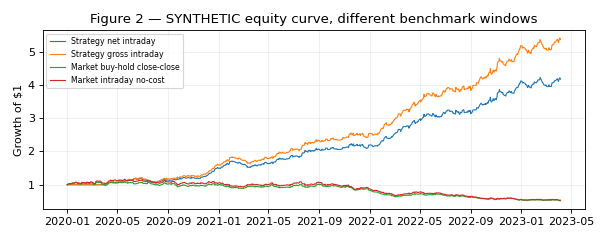

In [11]:
fig, ax = plt.subplots(figsize=(7.6, 3.0))
for key,label in [('equity_net','Strategy net intraday'),('equity_gross','Strategy gross intraday'),('equity_cc_benchmark','Market buy-hold close-close'),('equity_intraday_long','Market intraday no-cost')]:
    ax.plot(daily.index,daily[key],label=label,lw=1.0)
ax.set(title='Figure 2 — SYNTHETIC equity curve, different benchmark windows',ylabel='Growth of $1')
ax.legend(fontsize=7); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig('outputs/notebook_equity.png',dpi=80); plt.close(fig)
__notebook_image__='outputs/notebook_equity.png'
print('Figure 2: Positive synthetic P&L results from injected predictability.')

## 10. Robustness & Placebos

We predeclare cost stress, 10/20/30% ownership tails, owner categories and sector neutrality. A cost sensitivity plot is a mechanism check: a strategy with frequent round trips should lose performance as fees increase. **True** block-aware placebo p-values and factor-neutral tests require real data and are pending.

In [12]:
cost_rows = []
for bps in [1,2,5,10]:
    _, r = run_backtest(p,h,m,side_cost_bps=bps)
    cost_rows.append((bps,r['strategy_net']['sharpe'],r['strategy_net']['cagr']))
cost_df = pd.DataFrame(cost_rows,columns=['one_side_bps','net_sharpe','net_cagr'])
print(cost_df.round(4).to_string(index=False))

 one_side_bps  net_sharpe  net_cagr
            1      3.1348    0.5849
            2      2.8902    0.5270
            5      2.1524    0.3657
           10      0.9125    0.1336


Figure 3: Costs reduce the artificial gross alpha.


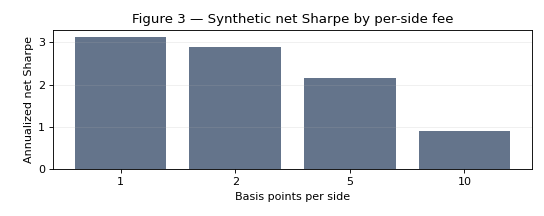

In [13]:
fig, ax = plt.subplots(figsize=(6.8, 2.7))
ax.bar(cost_df.one_side_bps.astype(str),cost_df.net_sharpe,color='#64748b')
ax.set(title='Figure 3 — Synthetic net Sharpe by per-side fee',xlabel='Basis points per side',ylabel='Annualized net Sharpe')
ax.grid(axis='y',alpha=.2); fig.tight_layout()
fig.savefig('outputs/notebook_costs.png',dpi=80); plt.close(fig)
__notebook_image__='outputs/notebook_costs.png'
print('Figure 3: Costs reduce the artificial gross alpha.')

In [14]:
cases=[]
for q in [0.1,0.2,0.3]:
    _,mr=run_backtest(p,h,m,q=q)
    cases.append((q,mr['strategy_net']['sharpe'],mr['predictive_hac']['p_hac']))
print(pd.DataFrame(cases,columns=['tail_fraction','net_sharpe','hac_p_value']).to_string(index=False))

 tail_fraction  net_sharpe  hac_p_value
           0.1    2.740563 6.601710e-12
           0.2    2.890241 6.367691e-13
           0.3    3.122079 6.016035e-14


## 11. Regime Sensitivity

The synthetic fixture has no recession, VIX, funding-tightness or international regimes. The authors' public abstract reports heterogeneity, but the present simulation does not verify it. A chronological last-30% split below is descriptive, **not a genuinely untouched holdout**, since the code and hyperparameters were designed with synthetic behavior in mind.

In [15]:
print('First 70% net:', metrics['strategy_net_first_70pct'])
print('Last 30% net:', metrics['strategy_net_last_30pct'])
print('Bootstrap 95% net Sharpe interval:', metrics['sharpe_block_bootstrap_95pct'])

First 70% net: {'days': 595, 'cumulative_return': 1.8778499007582203, 'cagr': 0.5646919880885153, 'sharpe': 3.1132948589760727, 'sortino': 5.199710508276257, 'max_drawdown': -0.12324345773361534, 'hit_rate': 0.43529411764705883}
Last 30% net: {'days': 255, 'cumulative_return': 0.44894977341245923, 'cagr': 0.44264204801229945, 'sharpe': 2.4036879228280816, 'sortino': 4.014791863014998, 'max_drawdown': -0.06517123438458516, 'hit_rate': 0.45098039215686275}
Bootstrap 95% net Sharpe interval: [1.8900254553494877, 4.018014689020044]


## 12. Bias Audit & Verdict

Real threats include survival and CUSIP mapping, 13F delayed public availability, manager-type endogeneity, betas/momentum/industry risk, short book invisibility, index-futures arbitrage and true transaction costs. Synthetic certainty does not establish an economic mechanism. **Verdict: reproducible synthetic software validation; investable alpha unproven.**

In [16]:
assert (daily['position_open'] == daily['decision_close'].shift(1).fillna(0)).all()
assert (daily['trading_cost'] >= 0).all()
assert (daily['gross_return'] >= daily['net_return']).all()
print('Execution shift, nonnegative trading costs and gross-net ordering: ALL PASS')

Execution shift, nonnegative trading costs and gross-net ordering: ALL PASS


## 13. Reproduction

`python -m unittest discover -s tests -v`; `python make_synthetic_fixture.py --out data/synthetic`; `python backtest.py --prices ... --holdings ... --market ... --source-label synthetic`; `python robustness.py ...`. `python build_notebook.py` re-executes and stores cell outputs. All paths are local to this study folder; no vendor data, tokens or credentials are committed.

In [17]:
print('Notebook code cells executed in this regeneration; generated outputs saved in research.ipynb.')
print('Independent unit test command: python -m unittest discover -s tests -v')

Notebook code cells executed in this regeneration; generated outputs saved in research.ipynb.
Independent unit test command: python -m unittest discover -s tests -v


## 14. Next-Stage Protocol

Obtain SEC/WRDS historical manager-level data with actual filing timestamps, CRSP delisting-inclusive returns and S&P 500 ETF market sessions; read all original empirical tables; replicate exact portfolio construction; freeze parameters on a training period and test a genuinely untouched holdout with factor controls, funding state masks, placebo and effective trading costs. Treat any failure as publishable negative evidence.

## 15. Sources & Artifacts

- Chen & Yin (2026), *Between the Bells: Active Management and the Aggregation of Market-Wide Information*: https://ssrn.com/abstract=7367200
- SEC Form 13F datasets: https://www.sec.gov/data-research/sec-markets-data/form-13f-data-sets
- SEC investor guide: https://www.investor.gov/introduction-investing/investing-basics/glossary/form-13f-reports-filed-institutional-investment
- Source register: `data_sources.csv`; full methodology `DETAILS.md`; source code `backtest.py`; tests `tests/test_backtest.py`; synthetic scorecard `results_synthetic/RESULTS.md`.

**Do not quote synthetic metrics as empirical finance results.**